# IF25-40305: Sistem Teknologi Multimedia (STM)
## Modul 07 — Struktur Data Citra Digital & Warna: ndarray, Bit Depth, I/O, HSV & Histogram

**Institut Teknologi Sumatera (ITERA) — Program Studi Informatika**
*Materi Kuliah & Hands-on Lab Semester Ganjil 2026/2027 · Pertemuan 6*

---

### 🎯 Capaian Pembelajaran Modul 07:
1. Menjelaskan citra digital sebagai **matriks numerik** (`numpy.ndarray`) berbentuk `(H, W, C)` dan memeriksa atribut `shape`, `dtype`, `ndim`, `size`, `nbytes`.
2. Menerapkan **indexing & slicing** dengan benar, termasuk perbedaan urutan `img[y, x]` (NumPy) vs titik `(x, y)` (OpenCV) serta jebakan *view vs copy*.
3. Memahami **bit depth** dan **tipe data** (`uint8`, `uint16`, `float32`), serta menghindari *overflow* `uint8` saat aritmetika citra.
4. Menggunakan **`cv2.imread` / `cv2.imwrite`** secara aman (flag, pengecekan `None`, urutan BGR) dan mengukur trade-off **PNG vs JPEG**.
5. Menganalisis warna melalui **channel splitting**, konversi **Grayscale** (BT.601) dan **HSV**, lalu melakukan **segmentasi warna** dengan `cv2.inRange`.
6. Menghitung dan membaca **histogram** citra (grayscale, per kanal, hue) beserta **CDF** sebagai jembatan menuju perbaikan kontras.

> 📎 Slide pendamping: *Pertemuan 6 — Struktur Data Citra Digital & Warna* (mctm.web.id/stm). Seluruh angka pada slide dihitung dari citra dan kode yang sama dengan notebook ini.

## 1. Import Library & Persiapan Lingkungan

Modul ini hanya memakai pustaka inti yang sudah ada di `requirements.txt`: **`opencv-python`** (I/O dan konversi warna), **`numpy`** (array), dan **`matplotlib`** (visualisasi).

Citra contoh berada di folder `image/`. Seluruhnya berlisensi **CC0 / domain publik** dan berasal dari koleksi data `scikit-image` — lihat `image/CREDITS.md`.

In [1]:
import os
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Konfigurasi visualisasi konsisten
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = False

# Gambar inline disimpan sebagai JPEG agar ukuran berkas notebook tetap ringan
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 85}}

print(f"OpenCV     : {cv2.__version__}")
print(f"NumPy      : {np.__version__}")

OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)

OpenCV     : 5.0.0
NumPy      : 2.5.3


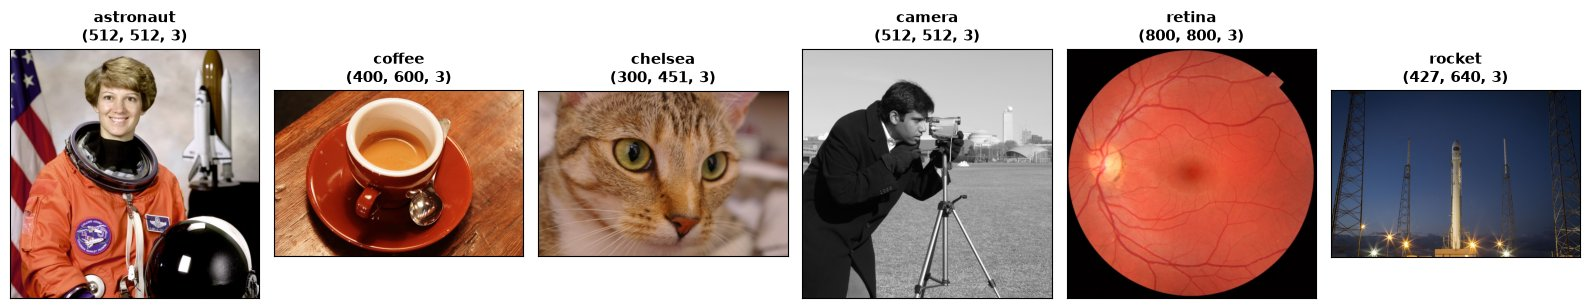

In [2]:
# Pencarian berkas citra defensif (notebook bisa dijalankan dari root repo atau folder notebook_handson)
def find_image(filename):
    possible_paths = [
        f"image/{filename}",
        f"notebook_handson/image/{filename}",
        f"../image/{filename}",
    ]
    return next((p for p in possible_paths if os.path.exists(p)), None)


def baca(filename, flag=cv2.IMREAD_COLOR):
    # cv2.imread TIDAK melempar error bila path salah -> kita periksa sendiri
    path = find_image(filename)
    img = cv2.imread(path, flag) if path else None
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan / gagal dibaca: {filename}")
    return img


def tampil(ax, img, judul=None):
    # Menampilkan citra OpenCV (BGR / grayscale) dengan benar di matplotlib
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_xticks([]); ax.set_yticks([])
    if judul:
        ax.set_title(judul, fontsize=11, fontweight='bold')


CITRA = ["astronaut.png", "coffee.png", "chelsea.png", "camera.png", "retina.jpg", "rocket.jpg"]
data = {n.split('.')[0]: baca(n) for n in CITRA}

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, (nama, img) in zip(axes, data.items()):
    tampil(ax, img, f"{nama}\n{img.shape}")
plt.tight_layout(); plt.show()

## 2. Citra sebagai Array NumPy

### 🔍 Anatomi `ndarray`
`cv2.imread` mengembalikan `numpy.ndarray`. Untuk citra berwarna bentuknya **`(H, W, C)`** = (tinggi/baris, lebar/kolom, kanal), dengan kanal berurutan **B, G, R**.

| Atribut | Arti |
|---|---|
| `img.shape` | `(H, W, C)` — atau `(H, W)` untuk grayscale |
| `img.dtype` | tipe data per elemen, biasanya `uint8` (0–255) |
| `img.ndim` | jumlah sumbu: 3 = berwarna, 2 = grayscale |
| `img.size` | jumlah elemen $H \cdot W \cdot C$ |
| `img.nbytes` | ukuran di RAM (byte) = `size × itemsize` |

In [3]:
img = data['astronaut']
gray = baca("astronaut.png", cv2.IMREAD_GRAYSCALE)

for nama, arr in [("Berwarna", img), ("Grayscale", gray)]:
    print(f"{nama:10s} shape={str(arr.shape):15s} dtype={arr.dtype}  ndim={arr.ndim}  "
          f"size={arr.size:7d}  nbytes={arr.nbytes:7d}  min={arr.min()}  max={arr.max()}")

H, W = img.shape[:2]          # cara aman: berlaku untuk citra berwarna maupun grayscale
print(f"\nTinggi H = {H} piksel, lebar W = {W} piksel")

Berwarna   shape=(512, 512, 3)   dtype=uint8  ndim=3  size= 786432  nbytes= 786432  min=0  max=255
Grayscale  shape=(512, 512)      dtype=uint8  ndim=2  size= 262144  nbytes= 262144  min=0  max=255

Tinggi H = 512 piksel, lebar W = 512 piksel


### 🔢 Melihat Piksel Sebagai Angka
Kita perbesar sebuah petak $9\times9$ di sekitar mata kucing. Setiap kotak adalah satu piksel `uint8`.

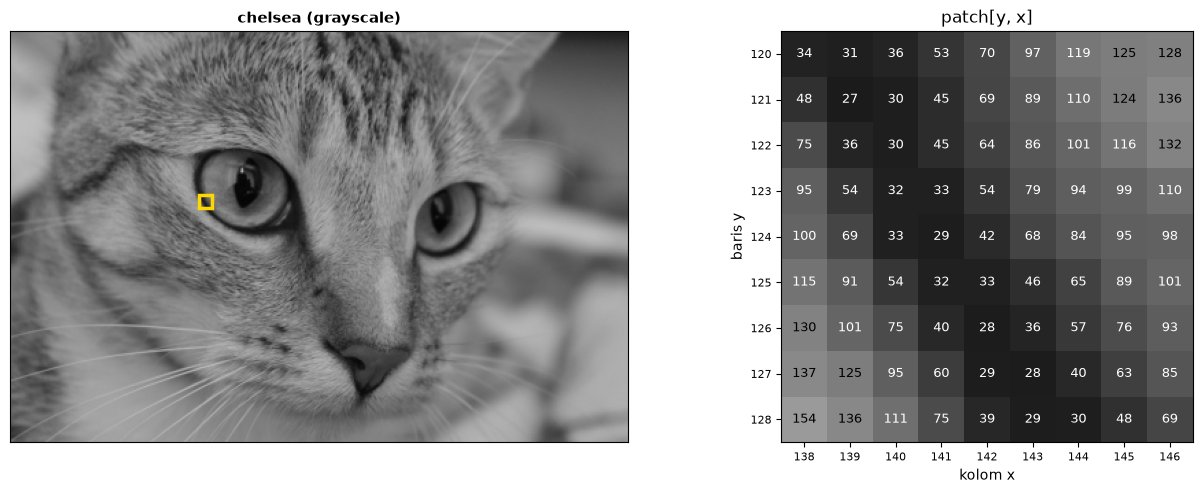

Nilai piksel di (y=120, x=138): 34


In [4]:
cat = cv2.cvtColor(data['chelsea'], cv2.COLOR_BGR2GRAY)
y0, x0, n = 120, 138, 9
patch = cat[y0:y0 + n, x0:x0 + n]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.4, 1]})
tampil(ax0, cat, "chelsea (grayscale)")
ax0.add_patch(Rectangle((x0 - .5, y0 - .5), n, n, fill=False, ec='gold', lw=2.5))
ax1.imshow(patch, cmap='gray', vmin=0, vmax=255)
for i in range(n):
    for j in range(n):
        v = patch[i, j]
        ax1.text(j, i, v, ha='center', va='center', fontsize=9, color='white' if v < 120 else 'black')
ax1.set_xticks(range(n), [x0 + j for j in range(n)], fontsize=8)
ax1.set_yticks(range(n), [y0 + i for i in range(n)], fontsize=8)
ax1.set_xlabel("kolom x"); ax1.set_ylabel("baris y"); ax1.set_title("patch[y, x]")
plt.tight_layout(); plt.show()

print("Nilai piksel di (y=120, x=138):", cat[120, 138])

### ✂️ Indexing & Slicing
- NumPy: **`img[y, x]`** — baris dulu, lalu kolom.
- Potongan (crop): `img[y0:y1, x0:x1]`.
- Satu kanal: `img[:, :, k]` dengan `k = 0` (B), `1` (G), `2` (R).

Piksel (y=100, x=200) -> BGR = [17 57 81]  ->  R=81, G=57, B=17


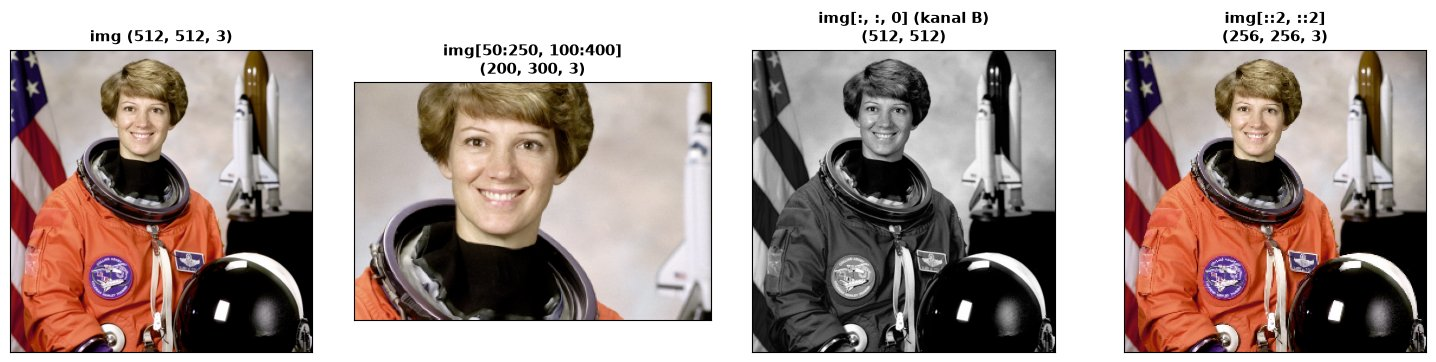

In [5]:
px = img[100, 200]
b, g, r = px
print(f"Piksel (y=100, x=200) -> BGR = {px}  ->  R={r}, G={g}, B={b}")

crop = img[50:250, 100:400]      # [y0:y1, x0:x1]
blue = img[:, :, 0]               # kanal B -> (H, W)
half = img[::2, ::2]              # ambil setiap 2 piksel (downsample kasar)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
tampil(axes[0], img, f"img {img.shape}")
tampil(axes[1], crop, f"img[50:250, 100:400]\n{crop.shape}")
tampil(axes[2], blue, f"img[:, :, 0] (kanal B)\n{blue.shape}")
tampil(axes[3], half, f"img[::2, ::2]\n{half.shape}")
plt.tight_layout(); plt.show()

### ⚠️ Jebakan 1 — Slicing Menghasilkan *View*, Bukan Salinan
Potongan hasil slicing **berbagi memori** dengan array aslinya. Mengubah potongan berarti mengubah citra asli. Gunakan `.copy()` bila Anda membutuhkan salinan independen.

roi berbagi memori dengan demo?  True
roi2 berbagi memori dengan aman? False


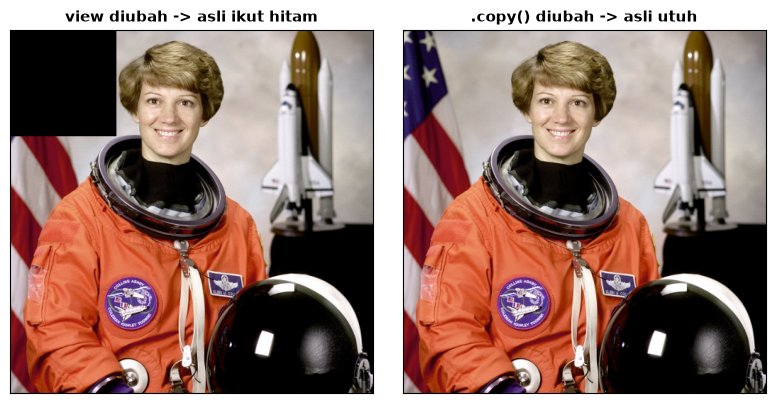

In [6]:
demo = img.copy()
roi = demo[0:150, 0:150]          # VIEW
roi[:] = 0                        # ... demo ikut berubah!

aman = img.copy()
roi2 = aman[0:150, 0:150].copy()  # SALINAN
roi2[:] = 0                       # aman tidak berubah

print("roi berbagi memori dengan demo? ", np.shares_memory(roi, demo))
print("roi2 berbagi memori dengan aman?", np.shares_memory(roi2, aman))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
tampil(axes[0], demo, "view diubah -> asli ikut hitam")
tampil(axes[1], aman, ".copy() diubah -> asli utuh")
plt.tight_layout(); plt.show()

### ⚠️ Jebakan 2 — NumPy `[y, x]` vs OpenCV `(x, y)`
Fungsi OpenCV yang menerima **titik** atau **ukuran** memakai urutan **kebalikannya**:
- `cv2.circle(img, (x, y), ...)`, `cv2.rectangle(img, (x0, y0), (x1, y1), ...)`
- `cv2.resize(img, (W_baru, H_baru))`

Warna piksel di canvas[y, x] = [  0 255 255] (kuning BGR = [0 255 255])
cv2.resize(canvas, (300, 100)).shape = (100, 300, 3)  -> H=100, W=300


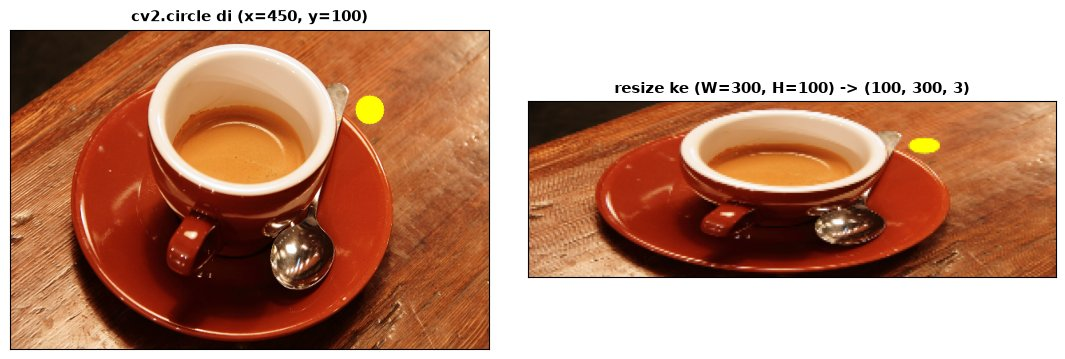

In [7]:
canvas = data['coffee'].copy()          # shape (400, 600, 3)
x, y = 450, 100
cv2.circle(canvas, (x, y), 18, (0, 255, 255), -1)           # titik (x, y)
print("Warna piksel di canvas[y, x] =", canvas[y, x], "(kuning BGR = [0 255 255])")

kecil = cv2.resize(canvas, (300, 100))                      # (W, H) !
print("cv2.resize(canvas, (300, 100)).shape =", kecil.shape, " -> H=100, W=300")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1.5, 1.5]})
tampil(axes[0], canvas, "cv2.circle di (x=450, y=100)")
tampil(axes[1], kecil, f"resize ke (W=300, H=100) -> {kecil.shape}")
plt.tight_layout(); plt.show()

### 💾 Berapa Memori yang Dibutuhkan? (Latihan 1 di slide)
$$\text{bytes} = H \times W \times C \times \frac{\text{bit}}{8}$$

In [8]:
def ukuran(h, w, c, dtype):
    return h * w * c * np.dtype(dtype).itemsize

kasus = [
    ("Foto HP 12 MP, uint8",              ukuran(3000, 4000, 3, np.uint8)),
    ("Foto HP 12 MP, float32",            ukuran(3000, 4000, 3, np.float32)),
    ("Foto HP 12 MP, float64",            ukuran(3000, 4000, 3, np.float64)),
    ("1 frame Full HD, uint8",            ukuran(1080, 1920, 3, np.uint8)),
    ("Video Full HD 30 fps 1 menit, raw", ukuran(1080, 1920, 3, np.uint8) * 30 * 60),
]
for nama, b in kasus:
    print(f"{nama:36s} {b:>15,d} B  = {b / 1e6:10.1f} MB")

# Bukti: alokasikan foto 12 MP sungguhan
foto = np.zeros((3000, 4000, 3), np.uint8)
print("\nnp.zeros((3000, 4000, 3), uint8).nbytes =", f"{foto.nbytes:,d}")
print("setelah .astype(np.float64)           =", f"{foto.astype(np.float64).nbytes:,d}")

Foto HP 12 MP, uint8                      36,000,000 B  =       36.0 MB
Foto HP 12 MP, float32                   144,000,000 B  =      144.0 MB
Foto HP 12 MP, float64                   288,000,000 B  =      288.0 MB
1 frame Full HD, uint8                     6,220,800 B  =        6.2 MB
Video Full HD 30 fps 1 menit, raw     11,197,440,000 B  =    11197.4 MB

np.zeros((3000, 4000, 3), uint8).nbytes = 36,000,000


setelah .astype(np.float64)           = 288,000,000


## 3. Bit Depth & Tipe Data

### 🎚️ Bit Depth = Jumlah Level Intensitas
Dengan $b$ bit per kanal tersedia $L = 2^b$ level. Mengurangi level memunculkan **posterisasi** (*banding*) — padanan visual dari *noise* kuantisasi pada audio.

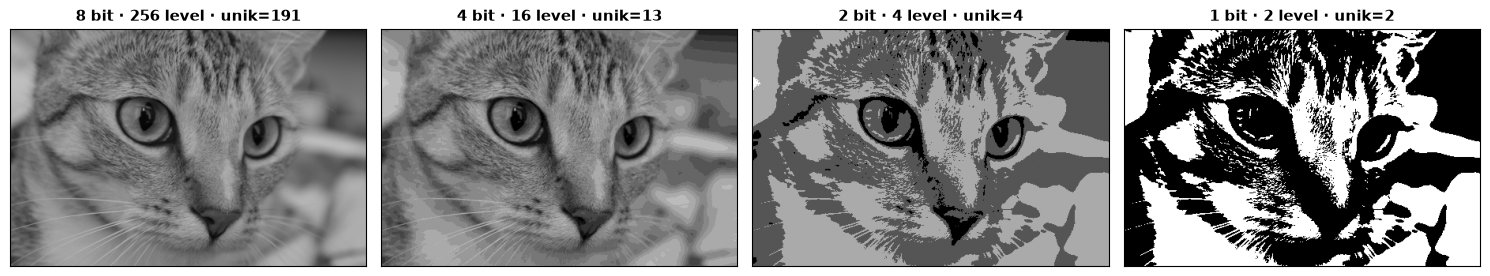

24-bit RGB (8 bit x 3 kanal) = 16,777,216 warna
30-bit HDR (10 bit x 3 kanal) = 1,073,741,824 warna


In [9]:
def kuantisasi(gray_img, bits):
    L = 2 ** bits
    q = np.floor(gray_img.astype(np.float32) / 256 * L)     # indeks level 0..L-1
    return (q * (255 / (L - 1))).astype(np.uint8)            # petakan kembali ke 0..255

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, b in zip(axes, [8, 4, 2, 1]):
    q = kuantisasi(cat, b)
    tampil(ax, q, f"{b} bit · {2**b} level · unik={len(np.unique(q))}")
plt.tight_layout(); plt.show()

print(f"24-bit RGB (8 bit x 3 kanal) = {256**3:,d} warna")
print(f"30-bit HDR (10 bit x 3 kanal) = {1024**3:,d} warna")

### 🧮 Rentang Setiap `dtype`

In [10]:
for t in [np.uint8, np.uint16, np.int16]:
    info = np.iinfo(t)
    print(f"{np.dtype(t).name:8s} min={info.min:>7d}  max={info.max:>7d}  byte={np.dtype(t).itemsize}")
for t in [np.float32, np.float64]:
    info = np.finfo(t)
    print(f"{np.dtype(t).name:8s} presisi ~{info.precision} digit desimal  byte={np.dtype(t).itemsize}")

uint8    min=      0  max=    255  byte=1
uint16   min=      0  max=  65535  byte=2
int16    min= -32768  max=  32767  byte=2
float32  presisi ~6 digit desimal  byte=4
float64  presisi ~15 digit desimal  byte=8


### ⚠️ Jebakan 3 — Overflow `uint8` (Latihan 2 di slide)
Aritmetika NumPy pada `uint8` bekerja **modulo 256** tanpa peringatan. Jalankan sel berikut dan bandingkan dengan tebakan Anda.

In [11]:
a = np.array([250, 100, 10], dtype=np.uint8)

ekspresi = {
    "a + 10":                                 a + 10,
    "a - 20":                                 a - 20,
    "a * 2":                                  a * 2,
    "(a.astype(np.int16) + 10).clip(0, 255)": (a.astype(np.int16) + 10).clip(0, 255),
    "a / 2":                                  a / 2,
    "a // 2":                                 a // 2,
}
for e, hasil in ekspresi.items():
    print(f"{e:40s} -> {str(hasil):20s} dtype={hasil.dtype}")

try:
    a + 300
except OverflowError as err:
    print(f"\na + 300 -> OverflowError: {err}")

a + 10                                   -> [  4 110  20]        dtype=uint8
a - 20                                   -> [230  80 246]        dtype=uint8
a * 2                                    -> [244 200  20]        dtype=uint8
(a.astype(np.int16) + 10).clip(0, 255)   -> [255 110  20]        dtype=int16
a / 2                                    -> [125.  50.   5.]     dtype=float64
a // 2                                   -> [125  50   5]        dtype=uint8

a + 300 -> OverflowError: Python integer 300 out of bounds for uint8


cv2.add sama dengan cara int16 + clip? True


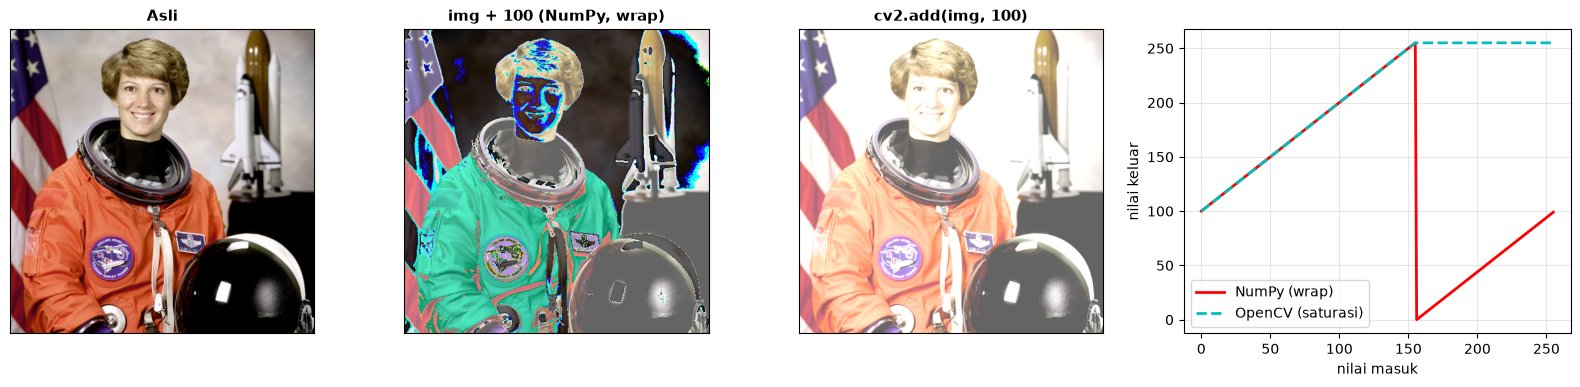

In [12]:
wrap = img + np.uint8(100)                          # NumPy: modulo 256
sat = cv2.add(img, np.full_like(img, 100))          # OpenCV: saturasi (dijepit di 255)
aman = np.clip(img.astype(np.int16) + 100, 0, 255).astype(np.uint8)
print("cv2.add sama dengan cara int16 + clip?", np.array_equal(sat, aman))

fig = plt.figure(figsize=(16, 3.8))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.2])
for k, (im, t) in enumerate([(img, "Asli"), (wrap, "img + 100 (NumPy, wrap)"), (sat, "cv2.add(img, 100)")]):
    tampil(fig.add_subplot(gs[k]), im, t)
ax = fig.add_subplot(gs[3])
x = np.arange(256)
ax.plot(x, (x + 100) % 256, 'r', lw=2, label='NumPy (wrap)')
ax.plot(x, np.minimum(x + 100, 255), 'c--', lw=2, label='OpenCV (saturasi)')
ax.set_xlabel("nilai masuk"); ax.set_ylabel("nilai keluar"); ax.grid(True, alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

### ✅ Pola Aman: Kerja di `float32` dalam Rentang $[0, 1]$
Naikkan presisi → hitung → **clip** → bulatkan → kembalikan ke `uint8`. Contoh: koreksi gamma $f' = f^{\gamma}$.

Perhatikan juga konvensi `matplotlib`: citra **float** dianggap berada di $[0, 1]$. Citra float bernilai 0–255 akan dijepit sehingga tampil (hampir) putih.

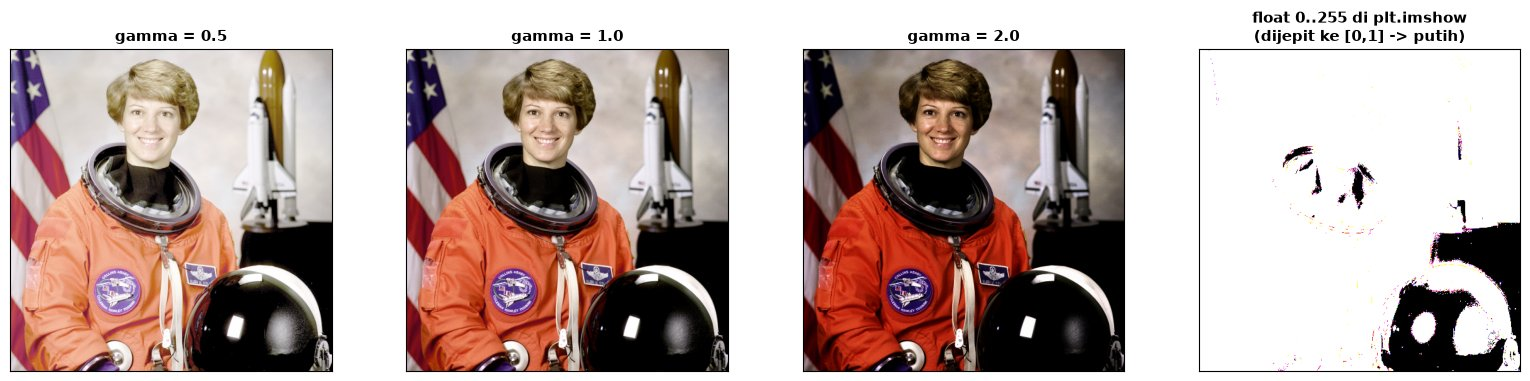

Bahaya truncate: [254] vs dibulatkan: [255]


In [13]:
f = img.astype(np.float32) / 255.0
hasil = {}
for gamma in [0.5, 1.0, 2.0]:
    g = np.clip(f ** gamma, 0, 1)
    hasil[gamma] = (g * 255).round().astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (gm, im) in zip(axes, hasil.items()):
    tampil(ax, im, f"gamma = {gm}")
salah = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)   # float tapi 0..255
axes[3].imshow(np.clip(salah, 0, 1)); axes[3].set_xticks([]); axes[3].set_yticks([])
axes[3].set_title("float 0..255 di plt.imshow\n(dijepit ke [0,1] -> putih)", fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

print("Bahaya truncate:", np.array([254.9]).astype(np.uint8), "vs dibulatkan:", np.array([254.9]).round().astype(np.uint8))

## 4. Membaca & Menyimpan Citra (I/O)

### 📥 Flag `cv2.imread`
| Flag | Hasil |
|---|---|
| `cv2.IMREAD_COLOR` (default) | selalu 3 kanal BGR, `uint8` |
| `cv2.IMREAD_GRAYSCALE` | 1 kanal |
| `cv2.IMREAD_UNCHANGED` | apa adanya: kanal **alpha** (BGRA) dan **16-bit** dipertahankan |

Untuk mendemonstrasikannya kita buat dua berkas: PNG **BGRA** (latar transparan) dan PNG **16-bit**.

In [14]:
# 1) PNG dengan kanal alpha: buat transparan di luar lingkaran
h, w = img.shape[:2]
alpha = np.zeros((h, w), np.uint8)
cv2.circle(alpha, (w // 2, h // 2), 220, 255, -1)
bgra = np.dstack([img, alpha])
cv2.imwrite(f"{OUT_DIR}/astronaut_bgra.png", bgra)

# 2) PNG 16-bit: skala 0..255 -> 0..65535
img16 = img.astype(np.uint16) * 257
cv2.imwrite(f"{OUT_DIR}/astronaut_16bit.png", img16)

for berkas in ["astronaut_bgra.png", "astronaut_16bit.png"]:
    p = f"{OUT_DIR}/{berkas}"
    for nama_flag in ["IMREAD_COLOR", "IMREAD_GRAYSCALE", "IMREAD_UNCHANGED"]:
        x = cv2.imread(p, getattr(cv2, nama_flag))
        print(f"{berkas:22s} {nama_flag:18s} shape={str(x.shape):15s} dtype={x.dtype}  max={x.max()}")
    print()

astronaut_bgra.png     IMREAD_COLOR       shape=(512, 512, 3)   dtype=uint8  max=255
astronaut_bgra.png     IMREAD_GRAYSCALE   shape=(512, 512)      dtype=uint8  max=255
astronaut_bgra.png     IMREAD_UNCHANGED   shape=(512, 512, 4)   dtype=uint8  max=255

astronaut_16bit.png    IMREAD_COLOR       shape=(512, 512, 3)   dtype=uint8  max=255
astronaut_16bit.png    IMREAD_GRAYSCALE   shape=(512, 512)      dtype=uint8  max=255
astronaut_16bit.png    IMREAD_UNCHANGED   shape=(512, 512, 3)   dtype=uint16  max=65535



### ⚠️ Jebakan 4 — `imread` Tidak Pernah Error
Path yang salah tidak menimbulkan exception: `cv2.imread` diam-diam mengembalikan `None`. Error baru muncul di baris berikutnya, jauh dari penyebabnya. Itulah alasan fungsi `baca()` di awal notebook memeriksa `None`.

In [15]:
hasil = cv2.imread("image/astronot.png")      # typo nama berkas
print("Hasil imread:", hasil)

try:
    print(hasil.shape)
except AttributeError as err:
    print("AttributeError:", err)

try:
    baca("astronot.png")
except FileNotFoundError as err:
    print("FileNotFoundError:", err, " <- pesan jelas, tepat di sumber masalah")

Hasil imread: None
AttributeError: 'NoneType' object has no attribute 'shape'
FileNotFoundError: Citra tidak ditemukan / gagal dibaca: astronot.png  <- pesan jelas, tepat di sumber masalah


[ WARN:0@1.718] global loadsave.cpp:278 findDecoder imread_('image/astronot.png'): can't open/read file: check file path/integrity


### 🎨 Pengingat: BGR vs RGB (Pertemuan 2)
`matplotlib` mengharapkan **RGB**. Tanpa konversi, kanal merah dan biru tertukar.

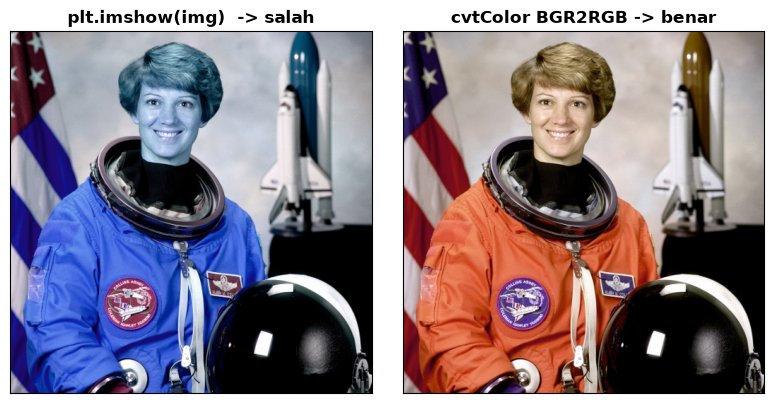

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img); axes[0].set_title("plt.imshow(img)  -> salah", fontweight='bold')
axes[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[1].set_title("cvtColor BGR2RGB -> benar", fontweight='bold')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 📦 Eksperimen: Kualitas JPEG vs Ukuran File
JPEG bersifat **lossy**: makin rendah `IMWRITE_JPEG_QUALITY`, makin kecil berkasnya dan makin besar kerusakannya. Kita ukur kualitas dengan **PSNR**:
$$\text{PSNR} = 10\log_{10}\frac{255^2}{\text{MSE}}\ \text{dB}$$
PNG bersifat **lossless**: hasil decode identik bit-per-bit.

In [17]:
kopi = data['coffee']
raw_kb = kopi.nbytes / 1024
png_path = f"{OUT_DIR}/kopi.png"
cv2.imwrite(png_path, kopi)
png_kb = os.path.getsize(png_path) / 1024
print(f"Array mentah : {raw_kb:7.1f} KB")
print(f"PNG          : {png_kb:7.1f} KB  (lossless, identik? {np.array_equal(cv2.imread(png_path), kopi)})\n")

qs = [5, 10, 20, 30, 50, 75, 90, 95, 100]
ukuran_kb, psnr, dec = [], [], {}
for q in qs:
    p = f"{OUT_DIR}/kopi_q{q:03d}.jpg"
    cv2.imwrite(p, kopi, [cv2.IMWRITE_JPEG_QUALITY, q])
    d = cv2.imread(p)
    ukuran_kb.append(os.path.getsize(p) / 1024)
    psnr.append(cv2.PSNR(kopi, d))
    dec[q] = d
    print(f"JPEG q={q:3d}: {ukuran_kb[-1]:7.1f} KB  rasio {raw_kb / ukuran_kb[-1]:6.1f}x  PSNR {psnr[-1]:5.1f} dB")

Array mentah :   703.1 KB
PNG          :   449.0 KB  (lossless, identik? True)

JPEG q=  5:     6.4 KB  rasio  109.8x  PSNR  23.5 dB
JPEG q= 10:     9.5 KB  rasio   74.4x  PSNR  26.0 dB
JPEG q= 20:    14.8 KB  rasio   47.5x  PSNR  28.0 dB
JPEG q= 30:    19.3 KB  rasio   36.4x  PSNR  29.1 dB
JPEG q= 50:    26.7 KB  rasio   26.3x  PSNR  30.5 dB
JPEG q= 75:    40.6 KB  rasio   17.3x  PSNR  32.4 dB


JPEG q= 90:    70.6 KB  rasio   10.0x  PSNR  35.5 dB
JPEG q= 95:   102.3 KB  rasio    6.9x  PSNR  37.5 dB
JPEG q=100:   210.2 KB  rasio    3.3x  PSNR  39.6 dB


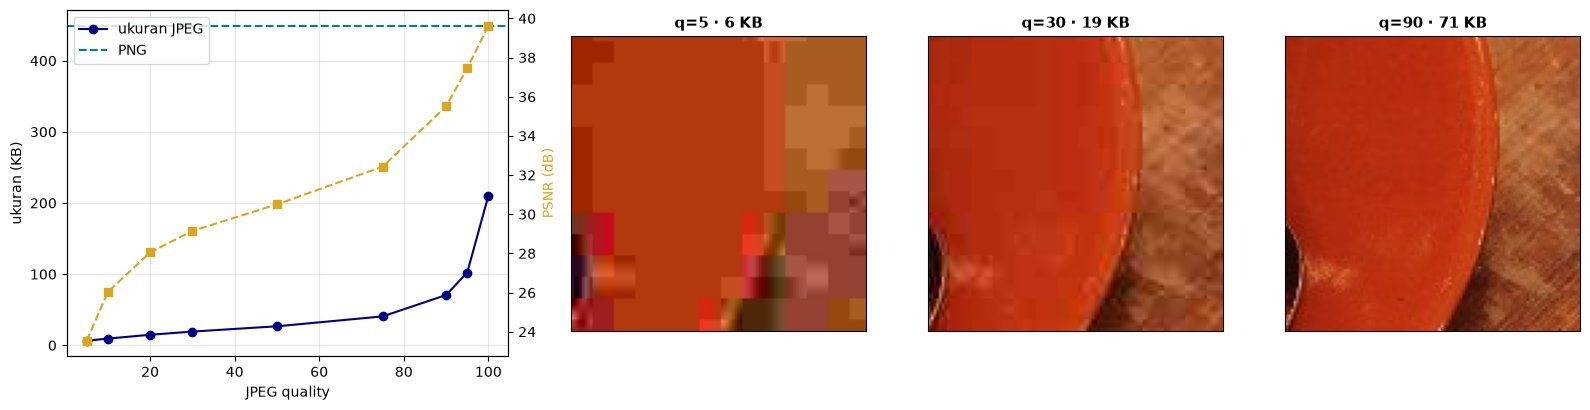

In [18]:
fig = plt.figure(figsize=(16, 4.2))
gs = fig.add_gridspec(1, 4, width_ratios=[1.5, 1, 1, 1])
ax = fig.add_subplot(gs[0])
ax.plot(qs, ukuran_kb, 'o-', color='navy', label='ukuran JPEG')
ax.axhline(png_kb, color='teal', ls='--', label='PNG')
ax.set_xlabel("JPEG quality"); ax.set_ylabel("ukuran (KB)"); ax.grid(True, alpha=.3); ax.legend(loc='upper left')
ax2 = ax.twinx(); ax2.plot(qs, psnr, 's--', color='goldenrod'); ax2.set_ylabel("PSNR (dB)", color='goldenrod')

cy, cx, cs = 190, 400, 110              # zoom ke tepi cawan & sendok
for k, q in enumerate([5, 30, 90]):
    tampil(fig.add_subplot(gs[k + 1]), dec[q][cy:cy + cs, cx:cx + cs], f"q={q} · {ukuran_kb[qs.index(q)]:.0f} KB")
plt.tight_layout(); plt.show()

### 🗜️ `IMWRITE_PNG_COMPRESSION` Hanya Mengubah Ukuran & Waktu
Level kompresi PNG (0–9) memengaruhi ukuran berkas dan waktu simpan, **bukan** kualitas — semuanya tetap lossless.

In [19]:
for level in [0, 1, 3, 6, 9]:
    p = f"{OUT_DIR}/kopi_png{level}.png"
    t0 = time.perf_counter()
    cv2.imwrite(p, kopi, [cv2.IMWRITE_PNG_COMPRESSION, level])
    dt = (time.perf_counter() - t0) * 1000
    identik = np.array_equal(cv2.imread(p), kopi)
    print(f"level {level}: {os.path.getsize(p) / 1024:7.1f} KB  waktu {dt:6.1f} ms  identik={identik}")

level 0:   704.7 KB  waktu    4.7 ms  identik=True
level 1:   464.8 KB  waktu   13.8 ms  identik=True
level 3:   455.7 KB  waktu   20.4 ms  identik=True


level 6:   446.4 KB  waktu   47.0 ms  identik=True
level 9:   445.8 KB  waktu   73.5 ms  identik=True


## 5. Ruang Warna

### 🔴🟢🔵 Channel Splitting
`cv2.split` memisahkan citra menjadi tiga citra grayscale. Piksel **terang** pada sebuah kanal berarti komponen warna tersebut besar. Untuk visualisasi berwarna, kanal lain bisa kita nolkan lalu `cv2.merge` kembali.

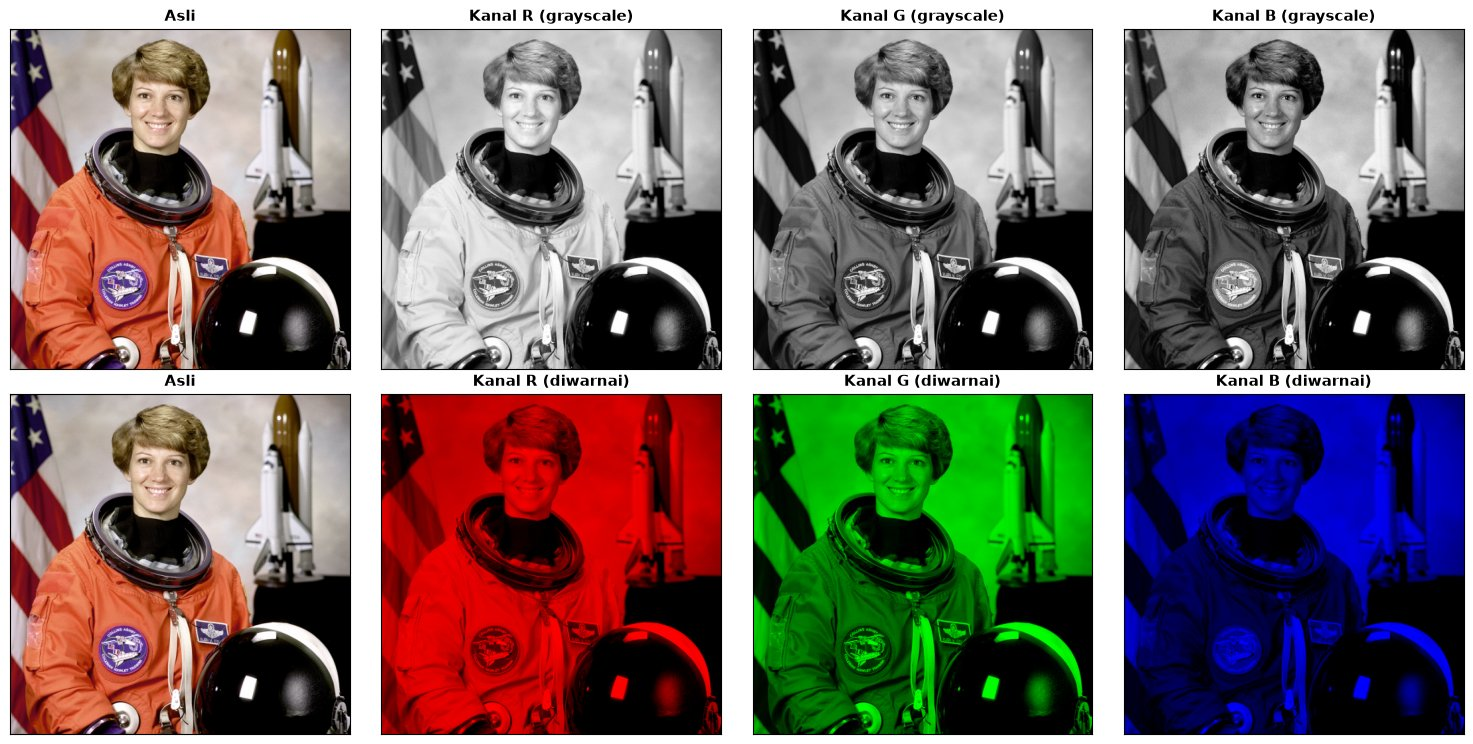

Rata-rata kanal pada baju oranye (y=380..450, x=40..120): {'R': 210, 'G': 93, 'B': 56}


In [20]:
b, g, r = cv2.split(img)
nol = np.zeros_like(b)
tint = {"B": cv2.merge([b, nol, nol]), "G": cv2.merge([nol, g, nol]), "R": cv2.merge([nol, nol, r])}

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
tampil(axes[0, 0], img, "Asli"); tampil(axes[1, 0], img, "Asli")
for k, (nama, ch) in enumerate([("R", r), ("G", g), ("B", b)]):
    tampil(axes[0, k + 1], ch, f"Kanal {nama} (grayscale)")
    tampil(axes[1, k + 1], tint[nama], f"Kanal {nama} (diwarnai)")
plt.tight_layout(); plt.show()

print("Rata-rata kanal pada baju oranye (y=380..450, x=40..120):",
      {n: int(c[380:450, 40:120].mean()) for n, c in [("R", r), ("G", g), ("B", b)]})

### 🩺 Studi Kasus: Citra Fundus Retina
Pada citra retina, kanal **R** cenderung jenuh dan kanal **B** gelap serta bising. Kanal **G** memberi kontras pembuluh darah terbaik, sehingga lazim dipakai sebagai input segmentasi pembuluh retina.

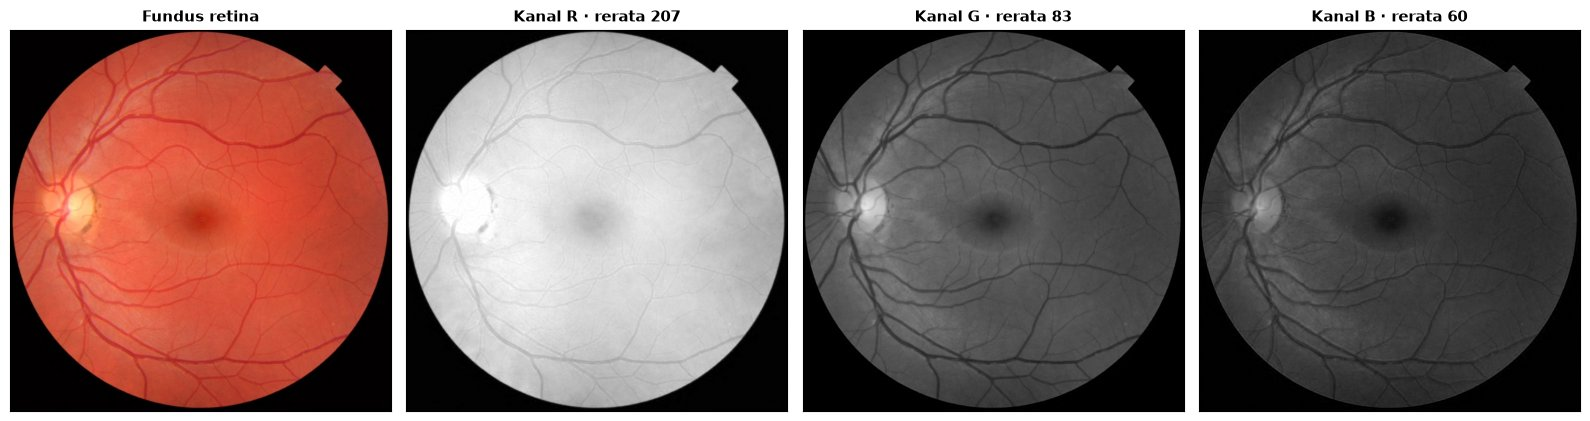

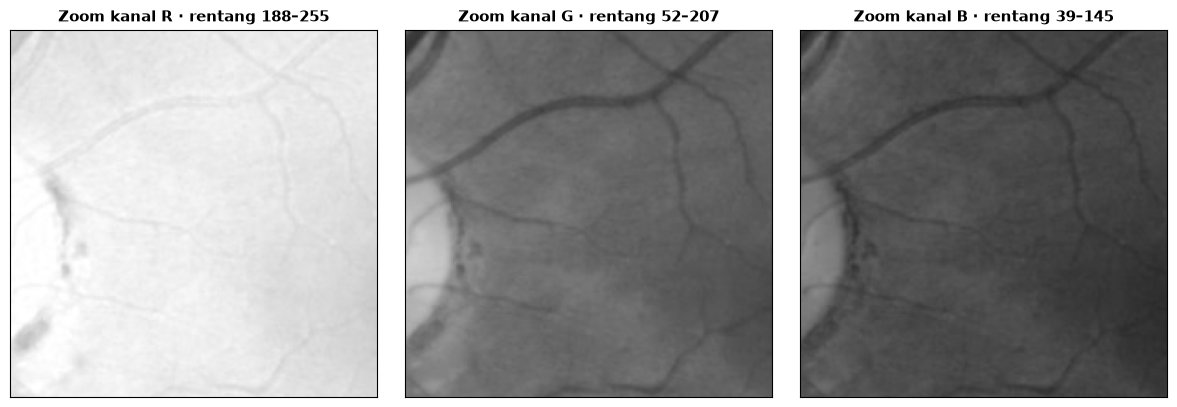

In [21]:
ret = data['retina']
rb, rg, rr = cv2.split(ret)
fov = rr > 30                                    # area lingkaran fundus (buang latar hitam)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
tampil(axes[0], ret, "Fundus retina")
for ax, (n, ch) in zip(axes[1:], [("R", rr), ("G", rg), ("B", rb)]):
    tampil(ax, ch, f"Kanal {n} · rerata {ch[fov].mean():.0f}")
plt.tight_layout(); plt.show()

# Perbesar area yang sama untuk membandingkan kontras pembuluh
ys, xs = slice(250, 450), slice(150, 350)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (n, ch) in zip(axes, [("R", rr), ("G", rg), ("B", rb)]):
    z = ch[ys, xs]
    tampil(ax, z, f"Zoom kanal {n} · rentang {z.min()}–{z.max()}")
plt.tight_layout(); plt.show()

### ⚫ Grayscale: Rata-rata vs Luminance Berbobot
- Naif: $Y = \frac{1}{3}(R + G + B)$
- **ITU-R BT.601** (dipakai `cv2.COLOR_BGR2GRAY`): $Y = 0{,}299R + 0{,}587G + 0{,}114B$

Mata manusia jauh lebih peka terhadap hijau daripada biru. Dengan rata-rata biasa, merah, hijau, dan biru murni menghasilkan abu-abu yang **sama**.

In [22]:
warna = {"Merah": (255, 0, 0), "Hijau": (0, 255, 0), "Biru": (0, 0, 255),
         "Kuning": (255, 255, 0), "Ungu": (128, 64, 200)}       # dalam RGB

print(f"{'Warna':8s} {'RGB':16s} {'rata-rata':>9s} {'BT.601':>7s} {'cvtColor':>9s}")
for nama, (R, G, B) in warna.items():
    avg = round((R + G + B) / 3)
    lum = 0.299 * R + 0.587 * G + 0.114 * B
    px = np.uint8([[[B, G, R]]])                                   # OpenCV butuh BGR
    cv = cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0, 0]
    print(f"{nama:8s} {str((R, G, B)):16s} {avg:9d} {lum:7.1f} {cv:9d}")

Warna    RGB              rata-rata  BT.601  cvtColor
Merah    (255, 0, 0)             85    76.2        76
Hijau    (0, 255, 0)             85   149.7       150
Biru     (0, 0, 255)             85    29.1        29
Kuning   (255, 255, 0)          170   225.9       226
Ungu     (128, 64, 200)         131    98.6        99


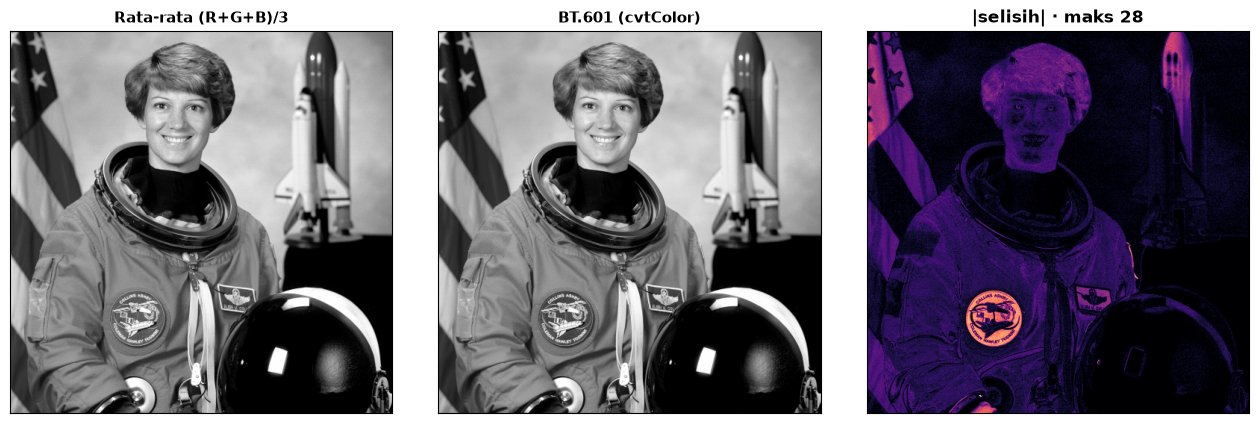

In [23]:
avg_gray = img.mean(axis=2).round().astype(np.uint8)
lum_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
selisih = cv2.absdiff(avg_gray, lum_gray)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
tampil(axes[0], avg_gray, "Rata-rata (R+G+B)/3")
tampil(axes[1], lum_gray, "BT.601 (cvtColor)")
axes[2].imshow(selisih, cmap='magma'); axes[2].set_xticks([]); axes[2].set_yticks([])
axes[2].set_title(f"|selisih| · maks {selisih.max()}", fontweight='bold')
plt.tight_layout(); plt.show()

### 🧪 Verifikasi Latihan 3: Awas Urutan Kanal
Piksel hasil `cv2.imread` bernilai `[40, 120, 200]` — urutannya **B, G, R**.

In [24]:
px = np.uint8([[[40, 120, 200]]])                     # BGR
B, G, R = px[0, 0].astype(float)
print("Rata-rata                :", (B + G + R) / 3)
print("BT.601 (urutan benar)    :", round(0.299 * R + 0.587 * G + 0.114 * B, 1))
print("BT.601 (salah, dikira RGB):", round(0.299 * B + 0.587 * G + 0.114 * R, 1))
print("cv2.cvtColor BGR2GRAY    :", cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0, 0])
print("cv2.cvtColor BGR2HSV     :", cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0, 0], "-> hue", cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0, 0, 0] * 2, "derajat (oranye)")

Rata-rata                : 120.0
BT.601 (urutan benar)    : 134.8
BT.601 (salah, dikira RGB): 105.2
cv2.cvtColor BGR2GRAY    : 135
cv2.cvtColor BGR2HSV     : [ 15 204 200] -> hue 30 derajat (oranye)


### 🌈 HSV: Memisahkan *Warna* dari *Cahaya*
- **H (Hue)**: jenis warna, berupa **sudut** (0° merah, 120° hijau, 240° biru) — bersifat melingkar.
- **S (Saturation)**: kemurnian warna (0 = abu-abu).
- **V (Value)**: kecerahan, $V = \max(R, G, B)$.

⚠️ **Skala OpenCV (`uint8`) berbeda dari teori**: $H \in [0, 179]$ (sudut dibagi 2 agar muat di `uint8`), $S, V \in [0, 255]$.

Warna    BGR              HSV OpenCV       Hue (derajat)
Merah    (0, 0, 255)      (0, 255, 255)              0°
Kuning   (0, 255, 255)    (30, 255, 255)            60°
Hijau    (0, 255, 0)      (60, 255, 255)           120°
Cyan     (255, 255, 0)    (90, 255, 255)           180°
Biru     (255, 0, 0)      (120, 255, 255)          240°
Magenta  (255, 0, 255)    (150, 255, 255)          300°
Abu-abu  (128, 128, 128)  (0, 0, 128)                0°


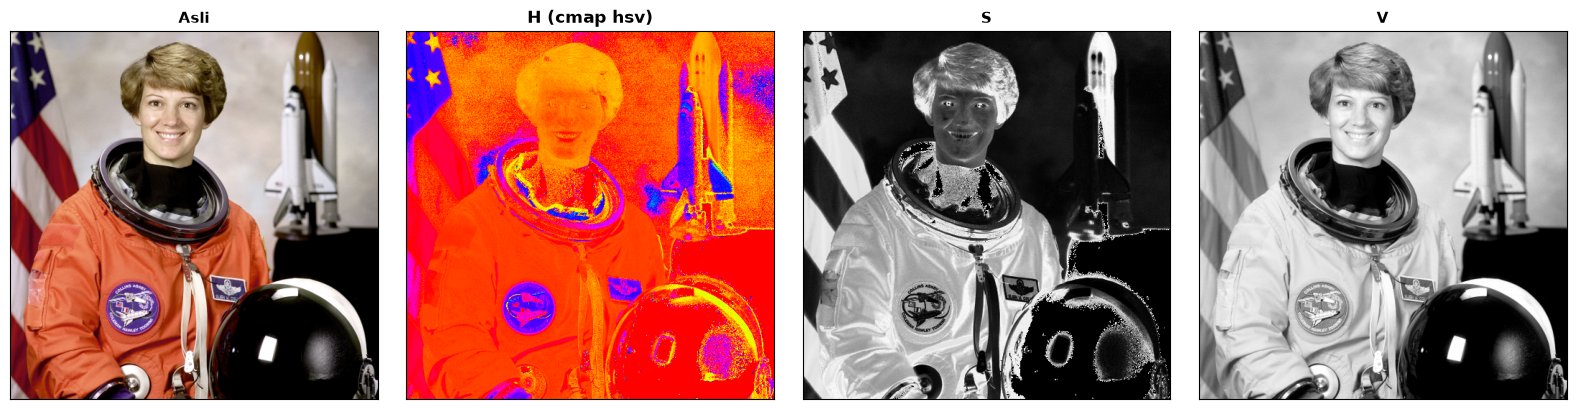

In [25]:
uji = {"Merah": (0, 0, 255), "Kuning": (0, 255, 255), "Hijau": (0, 255, 0),
       "Cyan": (255, 255, 0), "Biru": (255, 0, 0), "Magenta": (255, 0, 255), "Abu-abu": (128, 128, 128)}
print(f"{'Warna':8s} {'BGR':16s} {'HSV OpenCV':16s} {'Hue (derajat)':>13s}")
for nama, bgr in uji.items():
    h_, s_, v_ = (int(v) for v in cv2.cvtColor(np.uint8([[bgr]]), cv2.COLOR_BGR2HSV)[0, 0])
    print(f"{nama:8s} {str(bgr):16s} {str((h_, s_, v_)):16s} {h_ * 2:>11d}°")

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
Hc, Sc, Vc = cv2.split(hsv)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
tampil(axes[0], img, "Asli")
axes[1].imshow(Hc, cmap='hsv', vmin=0, vmax=179); axes[1].set_title("H (cmap hsv)", fontweight='bold')
tampil(axes[2], Sc, "S"); tampil(axes[3], Vc, "V")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 💡 Mengapa HSV? Bayangan Mengubah RGB, Bukan Hue
Kita ambil tiga titik pada baju oranye astronaut: bagian terang, sedang, dan dalam bayangan. Nilai RGB-nya berubah drastis, tetapi **Hue** hampir tetap.

1. Terang    RGB=(235,131, 95)   HSV=(  8,152,235)
2. Sedang    RGB=(209, 86, 49)   HSV=(  7,195,209)
3. Bayangan  RGB=(132, 32,  7)   HSV=(  6,241,132)


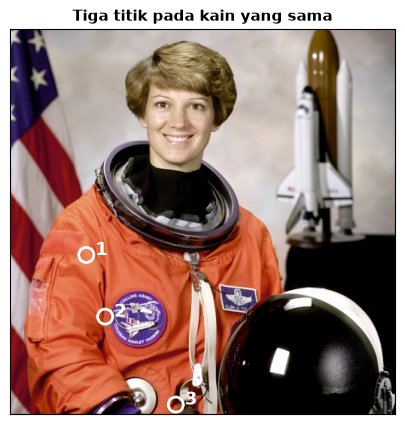

In [26]:
titik = {"Terang": (300, 101), "Sedang": (382, 126), "Bayangan": (499, 220)}   # (y, x)
fig, ax = plt.subplots(figsize=(5, 5))
tampil(ax, img, "Tiga titik pada kain yang sama")
for k, (nama, (y, x)) in enumerate(titik.items(), 1):
    b_, g_, r_ = img[y, x]
    h_, s_, v_ = hsv[y, x]
    ax.add_patch(plt.Circle((x, y), 10, fill=False, ec='white', lw=2))
    ax.text(x + 12, y, str(k), color='white', fontsize=13, fontweight='bold')
    print(f"{k}. {nama:9s} RGB=({r_:3d},{g_:3d},{b_:3d})   HSV=({h_:3d},{s_:3d},{v_:3d})")
plt.show()

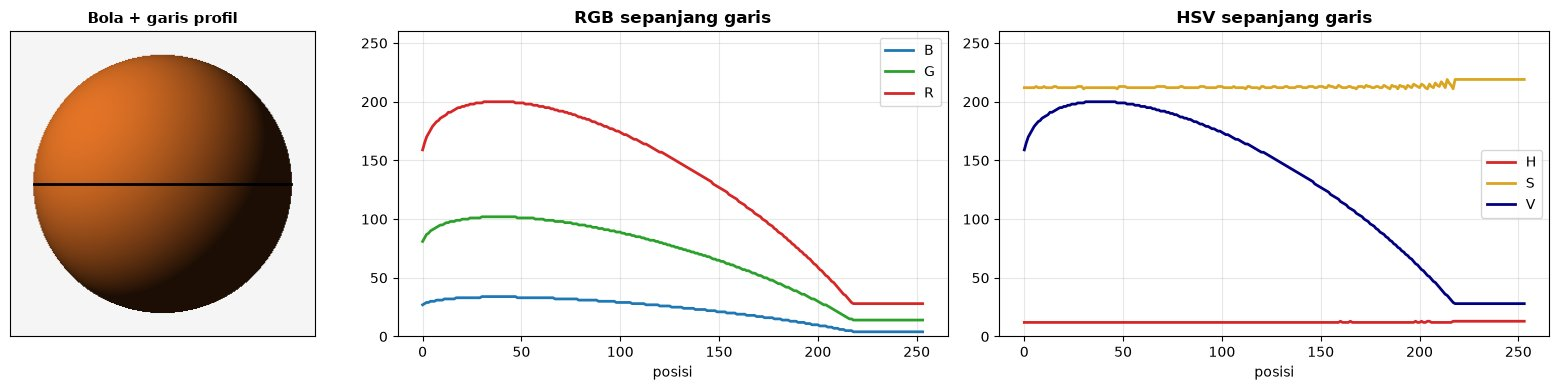

Rentang R : 28 - 200
Rentang H : 12 - 13


In [27]:
# Bola oranye sintetis dengan pencahayaan dari kiri atas
N = 300
yy, xx = np.mgrid[-1:1:N * 1j, -1:1:N * 1j]
inside = xx**2 + yy**2 <= 0.85**2
zz = np.sqrt(np.clip(0.85**2 - xx**2 - yy**2, 0, None)) / 0.85
L = np.array([-0.6, -0.5, 0.62]); L /= np.linalg.norm(L)
shade = np.clip(xx / 0.85 * L[0] + yy / 0.85 * L[1] + zz * L[2], 0, 1) * 0.85 + 0.12
bola = np.full((N, N, 3), 245, np.float32)
bola[inside] = np.array([40, 120, 235], np.float32) * shade[inside, None]       # BGR oranye
bola = bola.astype(np.uint8)
hsv_bola = cv2.cvtColor(bola, cv2.COLOR_BGR2HSV)

row = N // 2
xs_in = np.nonzero(inside[row])[0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={'width_ratios': [0.8, 1.2, 1.2]})
tampil(axes[0], bola, "Bola + garis profil"); axes[0].plot(xs_in[[0, -1]], [row, row], 'k-', lw=2)
for k, (n, c) in enumerate([("B", 'tab:blue'), ("G", 'tab:green'), ("R", 'tab:red')]):
    axes[1].plot(bola[row, xs_in, k], color=c, label=n, lw=2)
axes[1].set_title("RGB sepanjang garis", fontweight='bold'); axes[1].legend(); axes[1].set_ylim(0, 260)
for k, (n, c) in enumerate([("H", 'tab:red'), ("S", 'goldenrod'), ("V", 'navy')]):
    axes[2].plot(hsv_bola[row, xs_in, k], color=c, label=n, lw=2)
axes[2].set_title("HSV sepanjang garis", fontweight='bold'); axes[2].legend(); axes[2].set_ylim(0, 260)
for ax in axes[1:]:
    ax.grid(True, alpha=.3); ax.set_xlabel("posisi")
plt.tight_layout(); plt.show()

print("Rentang R :", bola[row, xs_in, 2].min(), "-", bola[row, xs_in, 2].max())
print("Rentang H :", hsv_bola[row, xs_in, 0].min(), "-", hsv_bola[row, xs_in, 0].max())

## 6. Segmentasi Warna dengan `cv2.inRange`

### 🧭 Pipeline
**BGR → HSV → `inRange(lo, hi)` → mask → (morfologi) → `bitwise_and`**

Langkah pertama: tentukan rentang hue dari **histogram hue** piksel berwarna (S cukup tinggi), bukan dengan menebak.

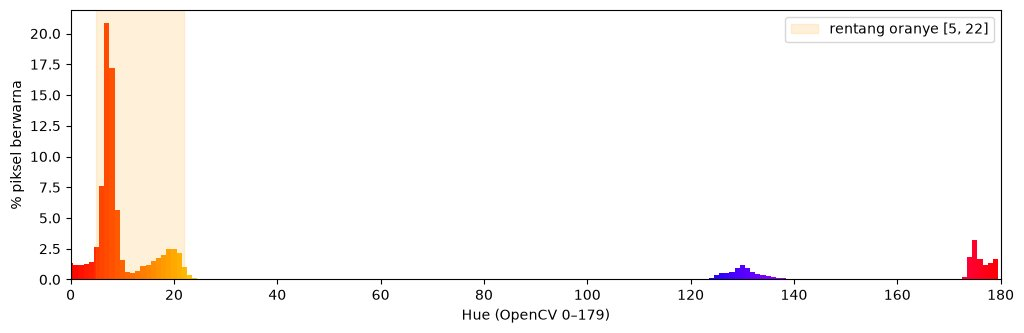

5 hue paling sering: [  7   8   6   9 175]


In [28]:
berwarna = (Sc > 80) & (Vc > 40)
hist_h = np.bincount(Hc[berwarna], minlength=180)

hue_bar = cv2.cvtColor(np.stack([np.arange(180, dtype=np.uint8), np.full(180, 255, np.uint8),
                                 np.full(180, 255, np.uint8)], 1)[None], cv2.COLOR_HSV2RGB)[0] / 255
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(np.arange(180), hist_h / hist_h.sum() * 100, width=1, color=hue_bar)
ax.axvspan(5, 22, color='orange', alpha=.15, label='rentang oranye [5, 22]')
ax.set_xlim(0, 180); ax.set_xlabel("Hue (OpenCV 0–179)"); ax.set_ylabel("% piksel berwarna"); ax.legend()
plt.show()

print("5 hue paling sering:", np.argsort(hist_h)[::-1][:5])

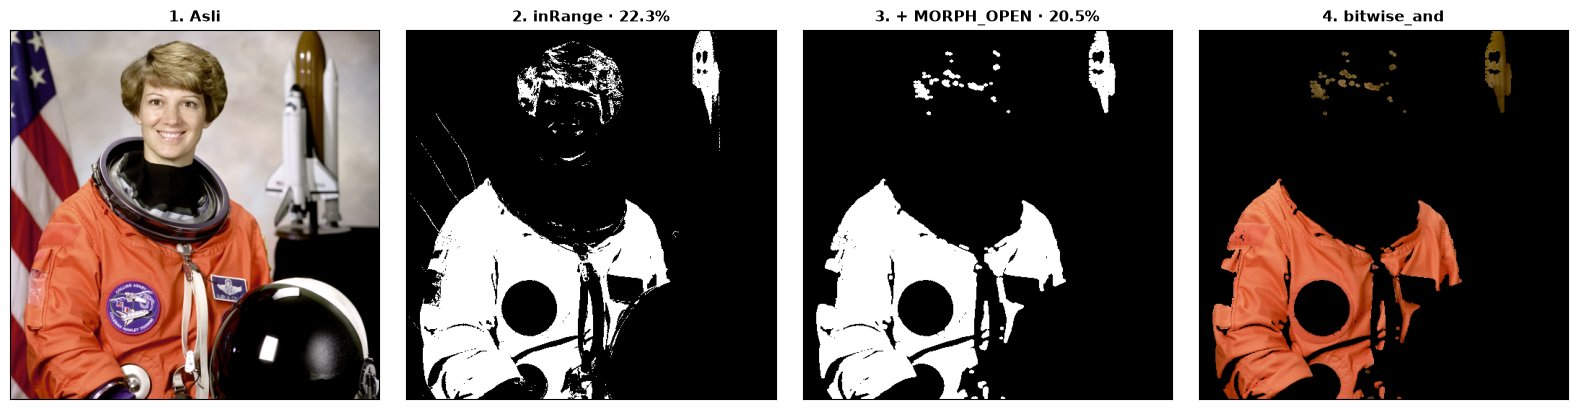

dtype mask: uint8 | nilai unik: [  0 255]


True

In [29]:
lo = np.array([5, 120, 70])      # H, S, V
hi = np.array([22, 255, 255])
mask = cv2.inRange(hsv, lo, hi)

k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
mask_bersih = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)       # buang bintik kecil
hasil = cv2.bitwise_and(img, img, mask=mask_bersih)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
tampil(axes[0], img, "1. Asli")
tampil(axes[1], mask, f"2. inRange · {(mask > 0).mean():.1%}")
tampil(axes[2], mask_bersih, f"3. + MORPH_OPEN · {(mask_bersih > 0).mean():.1%}")
tampil(axes[3], hasil, "4. bitwise_and")
plt.tight_layout(); plt.show()

print("dtype mask:", mask.dtype, "| nilai unik:", np.unique(mask))
cv2.imwrite(f"{OUT_DIR}/mask_oranye.png", mask_bersih)     # mask disimpan sebagai PNG (lossless)

### 🎛️ Bandingkan: Threshold Langsung di RGB
Bagaimana jika kita mencoba mencari "oranye" langsung dengan aturan RGB, misalnya *R > 180 dan G < 140 dan B < 110*? Bagian kain dalam bayangan (R jauh lebih kecil) akan terlewat.

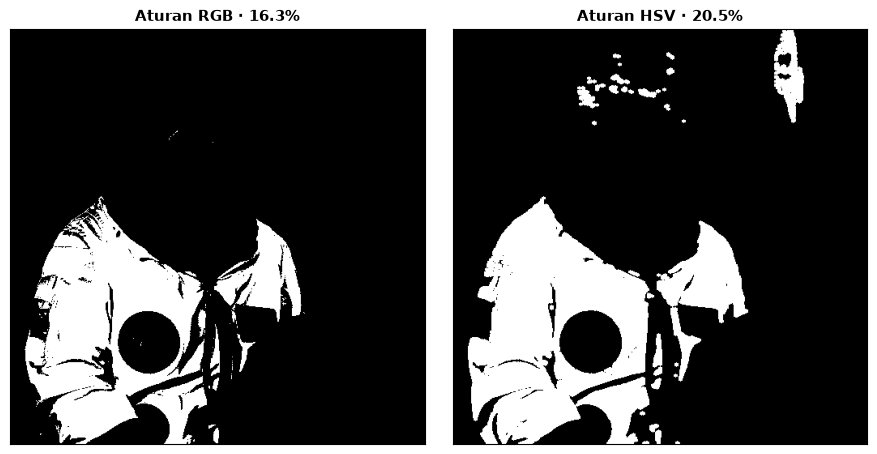

In [30]:
mask_rgb = ((r > 180) & (g < 140) & (b < 110)).astype(np.uint8) * 255

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
tampil(axes[0], mask_rgb, f"Aturan RGB · {(mask_rgb > 0).mean():.1%}")
tampil(axes[1], mask_bersih, f"Aturan HSV · {(mask_bersih > 0).mean():.1%}")
plt.tight_layout(); plt.show()

### ⚠️ Jebakan 5 — Merah Berada di Kedua Ujung Hue
Karena hue melingkar, warna merah muncul di sekitar **0** *dan* di sekitar **179**. Garis merah bendera pada citra astronaut berada di rentang $[170, 179]$, sedangkan baju di $[0, 10]$. Untuk menangkap "semua merah", gabungkan **dua** `inRange` dengan OR.

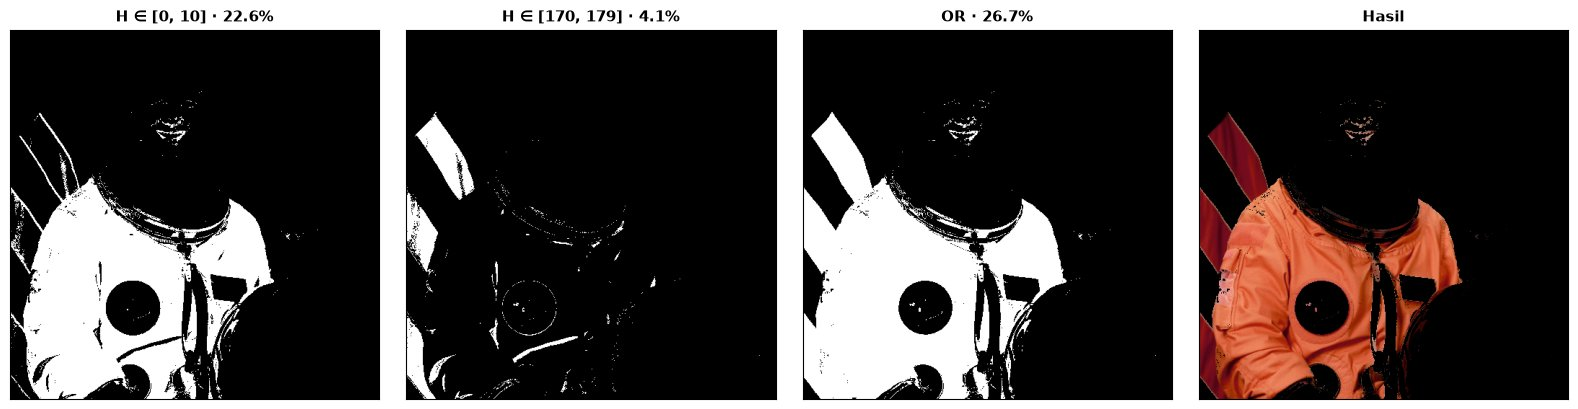

In [31]:
m1 = cv2.inRange(hsv, (0, 80, 40), (10, 255, 255))
m2 = cv2.inRange(hsv, (170, 80, 40), (179, 255, 255))
m_merah = cv2.bitwise_or(m1, m2)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
tampil(axes[0], m1, f"H ∈ [0, 10] · {(m1 > 0).mean():.1%}")
tampil(axes[1], m2, f"H ∈ [170, 179] · {(m2 > 0).mean():.1%}")
tampil(axes[2], m_merah, f"OR · {(m_merah > 0).mean():.1%}")
tampil(axes[3], cv2.bitwise_and(img, img, mask=m_merah), "Hasil")
plt.tight_layout(); plt.show()

### 🧪 Ruang Warna Lain (Sekilas): YCrCb & CIE Lab
- **YCrCb**: Y = luminance, Cr/Cb = selisih warna. Dipakai JPEG & video (subsampling kroma 4:2:0), populer untuk deteksi kulit.
- **CIE L\*a\*b\***: L\* = kecerahan, a\* = hijau↔merah, b\* = biru↔kuning. Dirancang seragam secara persepsi.

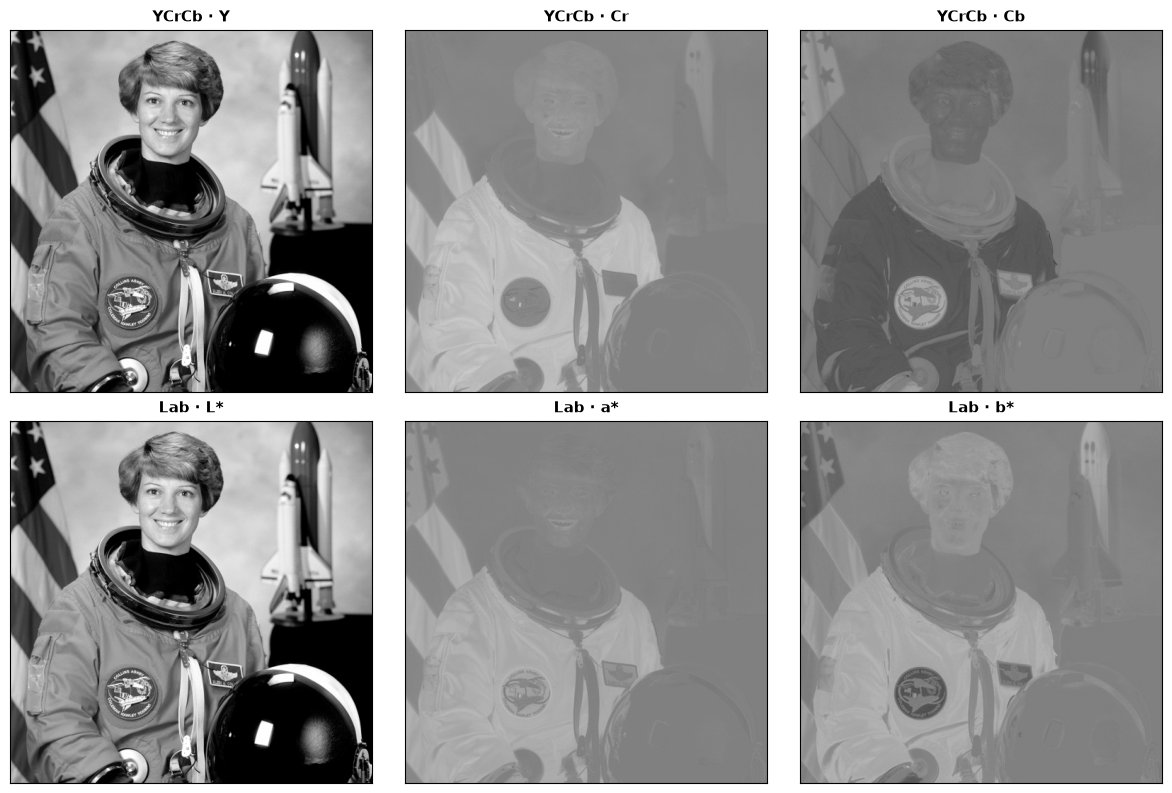

Selisih maks. Y (YCrCb) vs grayscale BT.601: 1 (hanya pembulatan)


In [32]:
ycc = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for j, n in enumerate(["Y", "Cr", "Cb"]):
    tampil(axes[0, j], ycc[..., j], f"YCrCb · {n}")
for j, n in enumerate(["L*", "a*", "b*"]):
    tampil(axes[1, j], lab[..., j], f"Lab · {n}")
plt.tight_layout(); plt.show()

print("Selisih maks. Y (YCrCb) vs grayscale BT.601:", int(cv2.absdiff(ycc[..., 0], lum_gray).max()), "(hanya pembulatan)")

## 7. Histogram Citra

### 📊 Definisi
$$h(k) = \#\{(x, y) : I(x, y) = k\}, \qquad p(k) = \frac{h(k)}{H \cdot W}, \qquad \sum_k p(k) = 1$$

Mulai dari citra mini $6\times 6$ 3-bit (nilai 0–7) yang sama dengan slide.

In [33]:
mini = np.array([[1, 1, 2, 2, 3, 3],
                 [1, 2, 2, 3, 3, 4],
                 [2, 2, 3, 3, 4, 6],
                 [2, 3, 3, 4, 6, 7],
                 [3, 3, 4, 6, 7, 7],
                 [3, 4, 6, 7, 7, 7]])
h_mini = np.bincount(mini.ravel(), minlength=8)
print("h(k)  =", h_mini, " jumlah =", h_mini.sum())
print("p(k)  =", np.round(h_mini / h_mini.sum(), 3))

h(k)  = [ 0  3  7 11  5  0  4  6]  jumlah = 36
p(k)  = [0.    0.083 0.194 0.306 0.139 0.    0.111 0.167]


### 🧮 Tiga Cara Menghitung Histogram
⚠️ Rentang ditulis `[0, 256]`, **bukan** `[0, 255]`: batas atas tidak termasuk, sehingga dengan `[0, 255]` piksel bernilai 255 **tidak terhitung sama sekali**.

In [34]:
gcam = data['camera'][..., 0]            # camera.png sudah abu-abu; ambil satu kanal

h1 = cv2.calcHist([gcam], [0], None, [256], [0, 256]).ravel()
h2, _ = np.histogram(gcam, bins=256, range=(0, 256))
h3 = np.bincount(gcam.ravel(), minlength=256)
print("Ketiga cara identik?", np.array_equal(h1, h2) and np.array_equal(h2, h3))

# Jebakan: range [0, 255] -> piksel bernilai 255 dibuang
h_salah = cv2.calcHist([gcam], [0], None, [256], [0, 255]).ravel()
print(f"Piksel bernilai 255           : {h3[255]:.0f}")
print(f"Total piksel, range [0, 256]  : {h1.sum():.0f}")
print(f"Total piksel, range [0, 255]  : {h_salah.sum():.0f}  -> {h1.sum() - h_salah.sum():.0f} piksel hilang")

Ketiga cara identik? True
Piksel bernilai 255           : 271
Total piksel, range [0, 256]  : 262144
Total piksel, range [0, 255]  : 261873  -> 271 piksel hilang


### 👀 Membaca Histogram: Gelap, Terang, Kontras Rendah, Kontras Tinggi

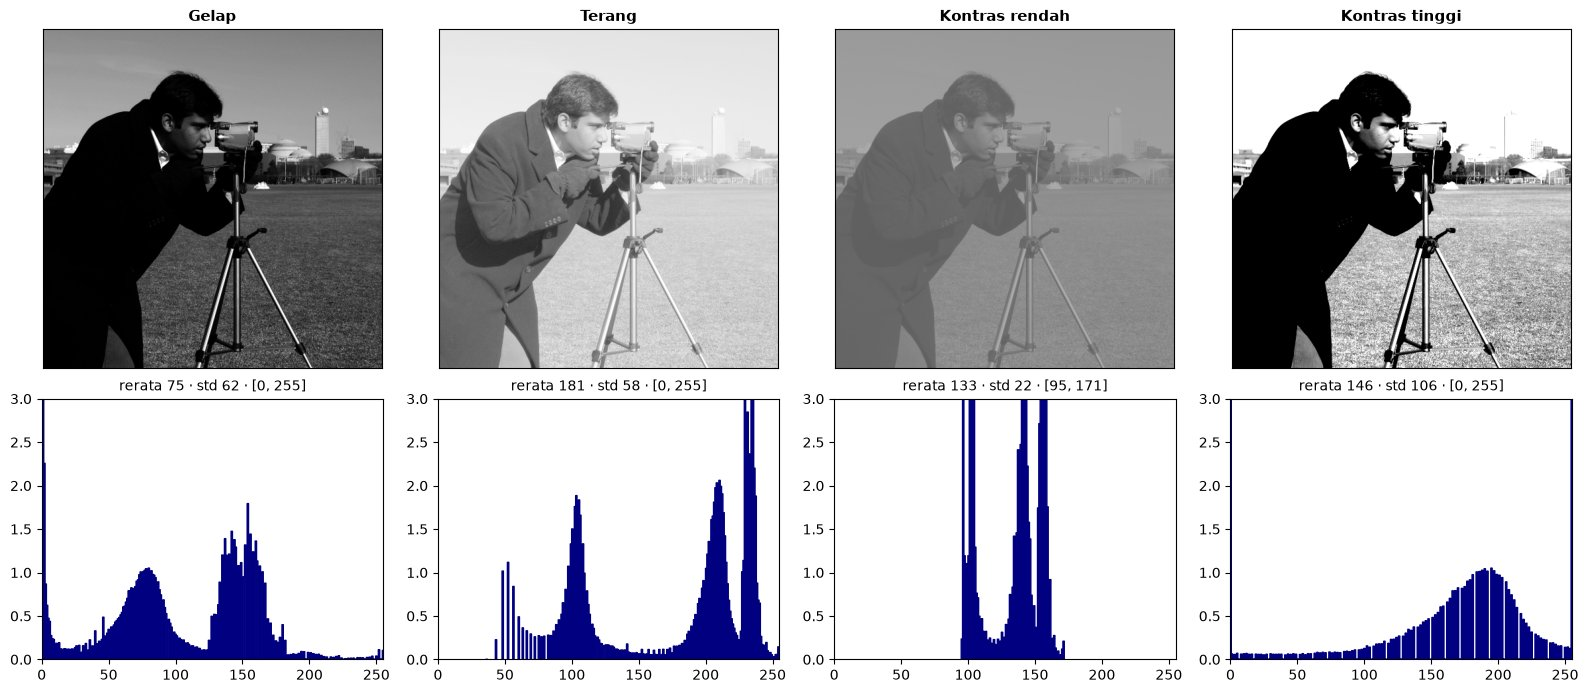

In [35]:
f = gcam.astype(np.float32) / 255
varian = {
    "Gelap":          (f ** 2.4) * 255,
    "Terang":         (f ** 0.4) * 255,
    "Kontras rendah": f * 255 * 0.3 + 95,
    "Kontras tinggi": (f - 0.5) * 2.2 * 255 + 128,
}
fig, axes = plt.subplots(2, 4, figsize=(16, 7), gridspec_kw={'height_ratios': [1.3, 1]})
for j, (nama, v) in enumerate(varian.items()):
    v = np.clip(v, 0, 255).astype(np.uint8)
    varian[nama] = v
    tampil(axes[0, j], v, nama)
    h = cv2.calcHist([v], [0], None, [256], [0, 256]).ravel()
    axes[1, j].fill_between(range(256), h / h.sum() * 100, step='mid', color='navy')
    axes[1, j].set_xlim(0, 255); axes[1, j].set_ylim(0, 3)
    axes[1, j].set_title(f"rerata {v.mean():.0f} · std {v.std():.0f} · [{v.min()}, {v.max()}]", fontsize=10)
plt.tight_layout(); plt.show()

### 🎨 Histogram Per Kanal
Posisi kurva tiap kanal memperlihatkan nuansa warna (*color cast*) sebuah foto.

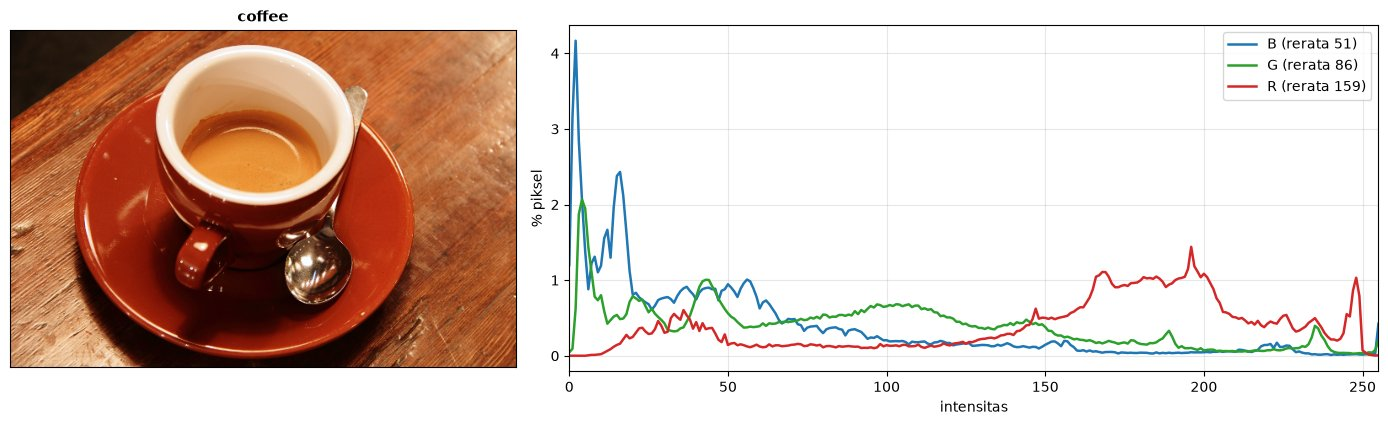

In [36]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})
tampil(ax0, kopi, "coffee")
for k, (n, c) in enumerate([("B", 'tab:blue'), ("G", 'tab:green'), ("R", 'tab:red')]):
    h = cv2.calcHist([kopi], [k], None, [256], [0, 256]).ravel()
    ax1.plot(h / h.sum() * 100, color=c, label=f"{n} (rerata {kopi[..., k].mean():.0f})", lw=1.8)
ax1.set_xlim(0, 255); ax1.set_xlabel("intensitas"); ax1.set_ylabel("% piksel"); ax1.grid(True, alpha=.3); ax1.legend()
plt.tight_layout(); plt.show()

### 🔀 Histogram Bukan Sidik Jari
Histogram tidak menyimpan **posisi** piksel. Mengacak seluruh piksel menghasilkan citra yang sama sekali berbeda dengan histogram yang **identik**.

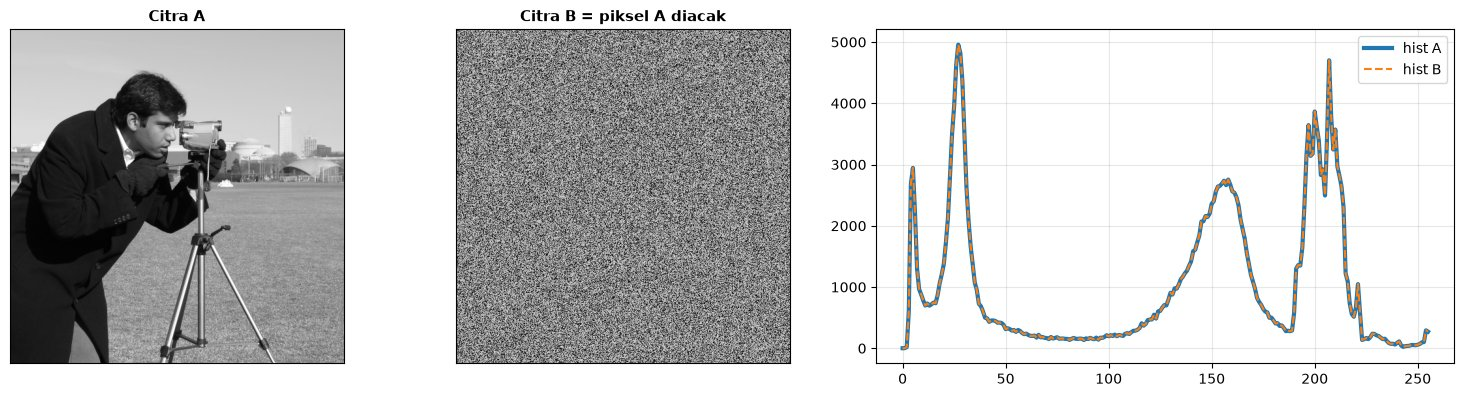

Histogram identik? True


In [37]:
rng = np.random.default_rng(6)
acak = rng.permutation(gcam.ravel()).reshape(gcam.shape)
ha = np.bincount(gcam.ravel(), minlength=256)
hb = np.bincount(acak.ravel(), minlength=256)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 1, 1.5]})
tampil(axes[0], gcam, "Citra A")
tampil(axes[1], acak, "Citra B = piksel A diacak")
axes[2].plot(ha, lw=3, label='hist A'); axes[2].plot(hb, '--', lw=1.5, label='hist B')
axes[2].legend(); axes[2].grid(True, alpha=.3)
plt.tight_layout(); plt.show()
print("Histogram identik?", np.array_equal(ha, hb))

### 🧩 Latihan 4 di Slide: Cocokkan Citra dengan Histogram
Sel berikut menampilkan histogram keempat citra **sesuai urutan** (bukan diacak seperti di slide), sehingga Anda bisa memeriksa jawaban dan alasannya.

1 · rocket   rerata   61.0  std  30.6  % piksel < 10:   0.4%
2 · retina   rerata   90.3  std  51.7  % piksel < 10:  23.1%
3 · gradien  rerata  127.0  std  73.8  % piksel < 10:   4.0%
4 · chelsea  rerata  119.5  std  32.1  % piksel < 10:   0.2%


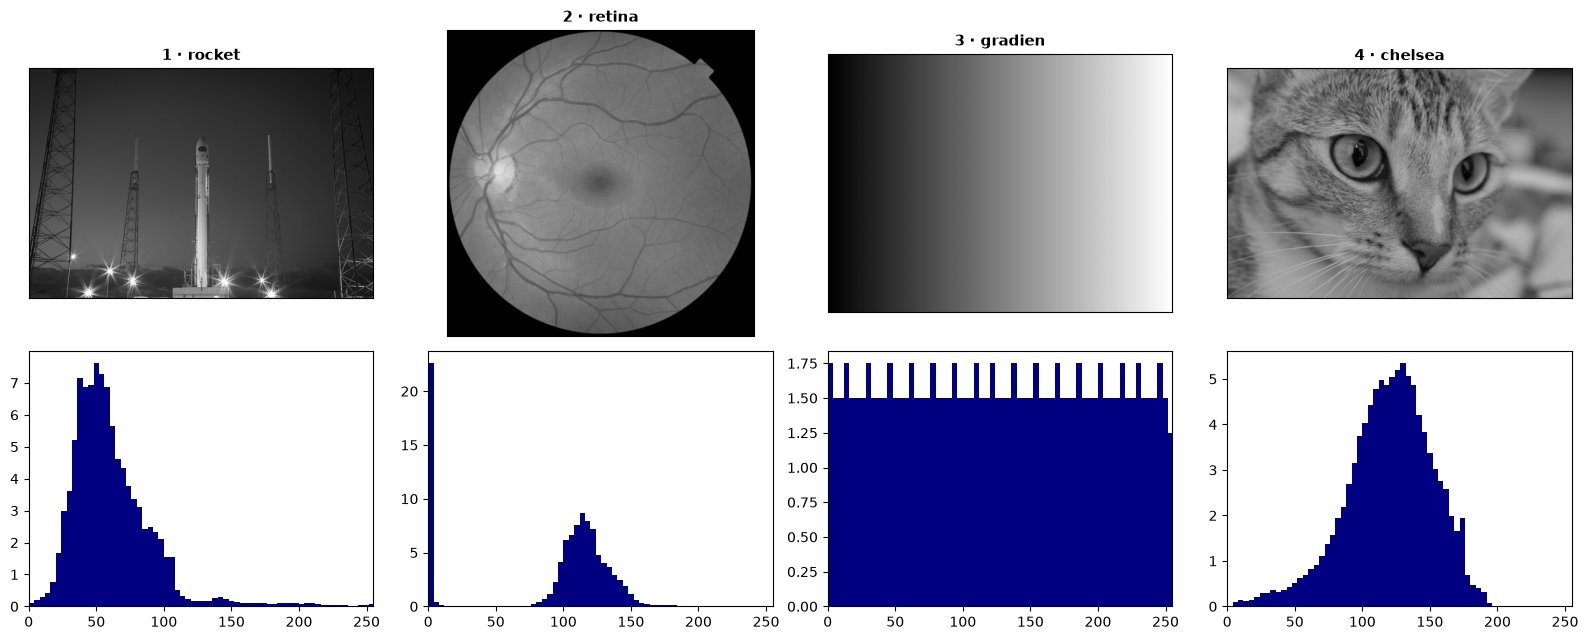

In [38]:
gradien = np.tile(np.linspace(0, 255, 400), (300, 1)).astype(np.uint8)
kuis = {
    "1 · rocket":  cv2.cvtColor(data['rocket'], cv2.COLOR_BGR2GRAY),
    "2 · retina":  cv2.cvtColor(data['retina'], cv2.COLOR_BGR2GRAY),
    "3 · gradien": gradien,
    "4 · chelsea": cv2.cvtColor(data['chelsea'], cv2.COLOR_BGR2GRAY),
}
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), gridspec_kw={'height_ratios': [1.2, 1]})
for j, (nama, g_) in enumerate(kuis.items()):
    tampil(axes[0, j], g_, nama)
    h = cv2.calcHist([g_], [0], None, [64], [0, 256]).ravel()
    axes[1, j].bar(np.arange(64) * 4 + 2, h / h.sum() * 100, width=4, color='navy')
    axes[1, j].set_xlim(0, 255)
    print(f"{nama:12s} rerata {g_.mean():6.1f}  std {g_.std():5.1f}  % piksel < 10: {(g_ < 10).mean():6.1%}")
plt.tight_layout(); plt.show()

### 📈 CDF: Jembatan ke Perbaikan Kontras (Pertemuan 8)
Fungsi distribusi kumulatif $\text{CDF}(k) = \sum_{j=0}^{k} p(j)$. **Histogram equalization** memakai CDF sebagai fungsi pemetaan
$$s_k = \operatorname{round}\big(255 \cdot \text{CDF}(k)\big)$$
sehingga rentang intensitas yang padat diregangkan. Di bawah ini kita membandingkan implementasi manual dengan `cv2.equalizeHist`.

Manual == cv2.equalizeHist ? True | selisih maks: 0


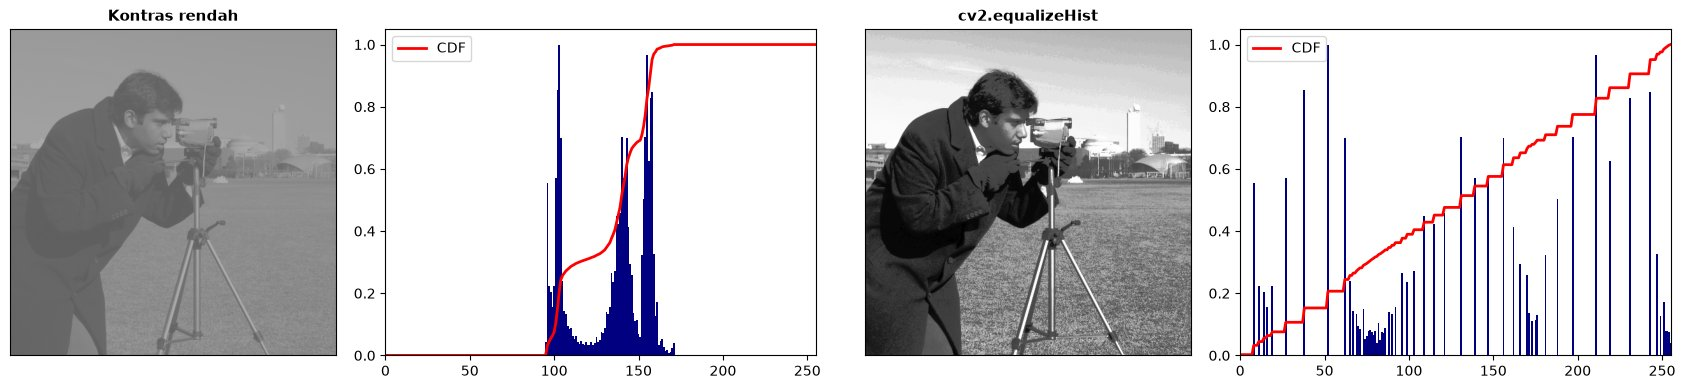

In [39]:
low = varian["Kontras rendah"]
h = np.bincount(low.ravel(), minlength=256)
cdf = h.cumsum() / h.sum()

# Implementasi manual (versi OpenCV menormalkan CDF relatif terhadap nilai CDF minimum)
cdf_min = cdf[cdf > 0].min()
lut = np.clip(np.round((cdf - cdf_min) / (1 - cdf_min) * 255), 0, 255).astype(np.uint8)
eq_manual = lut[low]                     # lookup table: setiap piksel dipetakan
eq_cv = cv2.equalizeHist(low)
print("Manual == cv2.equalizeHist ?", np.array_equal(eq_manual, eq_cv),
      "| selisih maks:", int(cv2.absdiff(eq_manual, eq_cv).max()))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={'width_ratios': [1, 1.3, 1, 1.3]})
for (ai, bi, im, t) in [(0, 1, low, "Kontras rendah"), (2, 3, eq_cv, "cv2.equalizeHist")]:
    tampil(axes[ai], im, t)
    hh = np.bincount(im.ravel(), minlength=256)
    axes[bi].bar(range(256), hh / hh.max(), width=1, color='navy')
    axes[bi].plot(hh.cumsum() / hh.sum(), 'r', lw=2, label='CDF')
    axes[bi].set_xlim(0, 255); axes[bi].legend(loc='upper left')
plt.tight_layout(); plt.show()

## 8. Rangkuman & Kebiasaan Baik

### 📌 Ringkasan Konsep Inti Modul 07:
1. **Citra = `ndarray` `(H, W, C)`**: indeks NumPy `img[y, x]` (baris dulu), sedangkan titik & ukuran pada fungsi OpenCV memakai `(x, y)` dan `(W, H)`. Slicing menghasilkan *view*; gunakan `.copy()` bila perlu.
2. **Bit depth** $b$ memberi $2^b$ level per kanal. `uint8` (0–255) adalah standar citra 8-bit; aritmetika NumPy pada `uint8` **wrap-around** modulo 256 tanpa peringatan.
3. **Pola aman aritmetika**: naikkan ke `int16`/`float32` → hitung → `clip` → `round` → kembalikan ke `uint8`, atau gunakan fungsi saturasi OpenCV (`cv2.add`).
4. **I/O**: `cv2.imread` mengembalikan `None` bila gagal — selalu periksa. `IMREAD_UNCHANGED` mempertahankan alpha & 16-bit. OpenCV memakai urutan **BGR**.
5. **PNG vs JPEG**: PNG lossless (cocok untuk mask, grafik, data latih); JPEG lossy dengan trade-off ukuran–kualitas yang diukur dengan **PSNR**; kualitas 85–90 adalah kompromi umum.
6. **Ruang warna**: RGB mencampur warna & kecerahan; **Grayscale BT.601** memberi bobot terbesar pada hijau; **HSV** memisahkan hue dari kecerahan sehingga kuat terhadap bayangan. Hue OpenCV berskala **0–179**, dan merah perlu **dua rentang**.
7. **Histogram** meringkas distribusi intensitas (kecerahan & kontras) tetapi kehilangan informasi spasial. Gunakan `range=[0, 256]`. **CDF** menjadi dasar histogram equalization.

### ✅ Lima Kebiasaan Baik
| # | Kebiasaan |
|---|---|
| 1 | Periksa `None` setelah `imread` |
| 2 | Cetak `shape` & `dtype` setiap kali ragu |
| 3 | Konversi warna secara eksplisit dengan `cv2.cvtColor` |
| 4 | Lakukan aritmetika di `int16`/`float32`, lalu `clip` |
| 5 | Simpan mask & hasil analisis sebagai PNG |

---
*Selamat! Anda telah menguasai fondasi representasi citra digital dan warna. Pada pertemuan berikutnya kita akan memindahkan **posisi** piksel melalui transformasi geometris (translasi, rotasi, scaling, flipping) serta membuat anotasi visual pada citra.*